In [ ]:
import pandas as pd

print("Projet Microsoft Financial Analysis")
print("Environnement Python opérationnel !")

Projet Microsoft Financial Analysis
Environnement Python opérationnel !


In [ ]:
import pandas as pd

df = pd.read_csv("/content/microsoft_financials.csv")

df.head()

,fiscal_year,revenue_usd_millions,operating_income_usd_millions,net_income_usd_millions,total_assets_usd_millions,total_liabilities_usd_millions,total_equity_usd_millions,operating_cash_flow_usd_millions,capital_expenditure_usd_millions,total_debt_usd_millions
0,2022,198270,83383,72738,364840,198298,166542,89035,-23886,49781
1,2023,211915,88523,72361,411976,205753,206223,87582,-28107,47237
2,2024,245122,109433,88136,512163,243686,268477,118548,-44477,51630
3,2025,281724,128528,101832,619003,275524,343479,136162,-64551,43151
4,2026,331839,155237,133749,758376,315989,442387,182935,-115948,40294


In [ ]:
# Vérifier les dimensions du dataset
print("Dimensions du dataset :", df.shape)

# Vérifier les types de données
print("\nTypes de données :")
print(df.dtypes)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(df.isnull().sum())

Dimensions du dataset : (5, 10)

Types de données :
fiscal_year                         int64
revenue_usd_millions                int64
operating_income_usd_millions       int64
net_income_usd_millions             int64
total_assets_usd_millions           int64
total_liabilities_usd_millions      int64
total_equity_usd_millions           int64
operating_cash_flow_usd_millions    int64
capital_expenditure_usd_millions    int64
total_debt_usd_millions             int64
dtype: object

Valeurs manquantes :
fiscal_year                         0
revenue_usd_millions                0
operating_income_usd_millions       0
net_income_usd_millions             0
total_assets_usd_millions           0
total_liabilities_usd_millions      0
total_equity_usd_millions           0
operating_cash_flow_usd_millions    0
capital_expenditure_usd_millions    0
total_debt_usd_millions             0
dtype: int64


In [ ]:
df["balance_check"] = (
    df["total_assets_usd_millions"]
    == df["total_liabilities_usd_millions"]
    + df["total_equity_usd_millions"]
)

print(df[["fiscal_year", "balance_check"]])

   fiscal_year  balance_check
0         2022           True
1         2023           True
2         2024           True
3         2025           True
4         2026           True


In [ ]:
# Calculer le taux de croissance du chiffre d'affaires en pourcentage
# pct_change() compare la valeur de l'année actuelle avec celle de l'année précédente
# * 100 permet de convertir le résultat en pourcentage

df["revenue_growth_%"] = df["revenue_usd_millions"].pct_change() * 100


# Calculer le taux de croissance du résultat opérationnel
# operating_income représente le bénéfice réalisé grâce aux activités opérationnelles

df["operating_income_growth_%"] = (
    df["operating_income_usd_millions"].pct_change() * 100
)


# Calculer le taux de croissance du bénéfice net
# net_income représente le bénéfice restant après les charges et les impôts

df["net_income_growth_%"] = (
    df["net_income_usd_millions"].pct_change() * 100
)


# Afficher uniquement les colonnes utiles pour comparer la croissance
# round(2) arrondit les résultats à deux chiffres après la virgule

df[[
    "fiscal_year",
    "revenue_growth_%",
    "operating_income_growth_%",
    "net_income_growth_%"
]].round(2)

,fiscal_year,revenue_growth_%,operating_income_growth_%,net_income_growth_%
0,2022,NaN,NaN,NaN
1,2023,6.88,6.16,-0.52
2,2024,15.67,23.62,21.80
3,2025,14.93,17.45,15.54
4,2026,17.79,20.78,31.34


In [ ]:
# Calculer la marge opérationnelle
# Elle mesure la part du chiffre d'affaires conservée après les charges opérationnelles
df["operating_margin_%"] = (
    df["operating_income_usd_millions"]
    / df["revenue_usd_millions"] * 100
)


# Calculer la marge nette
# Elle mesure la part du chiffre d'affaires qui reste en bénéfice net
df["net_margin_%"] = (
    df["net_income_usd_millions"]
    / df["revenue_usd_millions"] * 100
)


# Afficher les marges pour chaque exercice
# round(2) arrondit les résultats à deux décimales
df[[
    "fiscal_year",
    "operating_margin_%",
    "net_margin_%"
]].round(2)

,fiscal_year,operating_margin_%,net_margin_%
0,2022,42.06,36.69
1,2023,41.77,34.15
2,2024,44.64,35.96
3,2025,45.62,36.15
4,2026,46.78,40.31


In [ ]:
# Calculer le ROA (Return on Assets)
# Il mesure combien de bénéfice net est généré par les actifs de l'entreprise
df["ROA_%"] = (
    df["net_income_usd_millions"]
    / df["total_assets_usd_millions"] * 100
)

# Afficher le ROA pour chaque année
# round(2) arrondit les résultats à deux décimales
df[["fiscal_year", "ROA_%"]].round(2)

,fiscal_year,ROA_%
0,2022,19.94
1,2023,17.56
2,2024,17.21
3,2025,16.45
4,2026,17.64


In [ ]:
# Calculer le Debt Ratio (ratio d'endettement)
# Il mesure la part des actifs financée par les dettes
df["debt_ratio_%"] = (
    df["total_liabilities_usd_millions"]
    / df["total_assets_usd_millions"] * 100
)

# Afficher le ratio d'endettement pour chaque année
# round(2) arrondit les résultats à deux décimales
df[["fiscal_year", "debt_ratio_%"]].round(2)

,fiscal_year,debt_ratio_%
0,2022,54.35
1,2023,49.94
2,2024,47.58
3,2025,44.51
4,2026,41.67


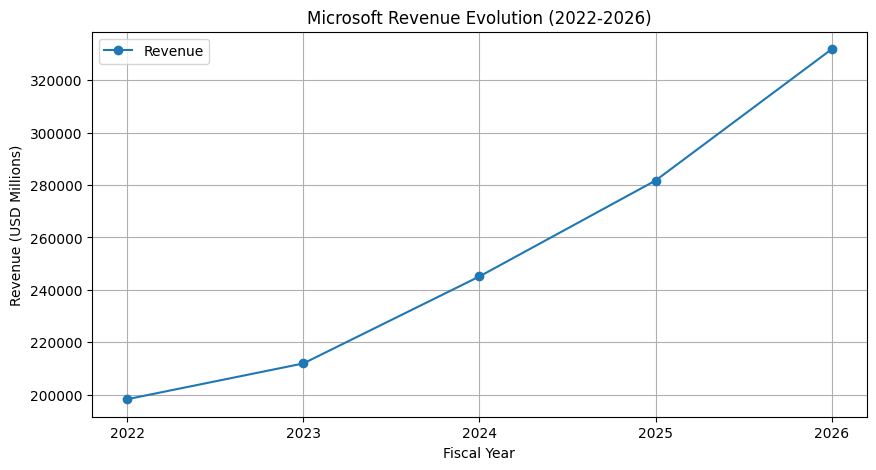

In [ ]:
import matplotlib.pyplot as plt

# Créer une figure pour le graphique
plt.figure(figsize=(10, 5))

# Tracer l'évolution du chiffre d'affaires
plt.plot(
    df["fiscal_year"],
    df["revenue_usd_millions"],
    marker="o",
    label="Revenue"
)

# Ajouter un titre et les noms des axes
plt.title("Microsoft Revenue Evolution (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Revenue (USD Millions)")

# Afficher les années sur l'axe horizontal
plt.xticks(df["fiscal_year"])

# Ajouter une grille et une légende
plt.grid(True)
plt.legend()

# Afficher le graphique
plt.show()

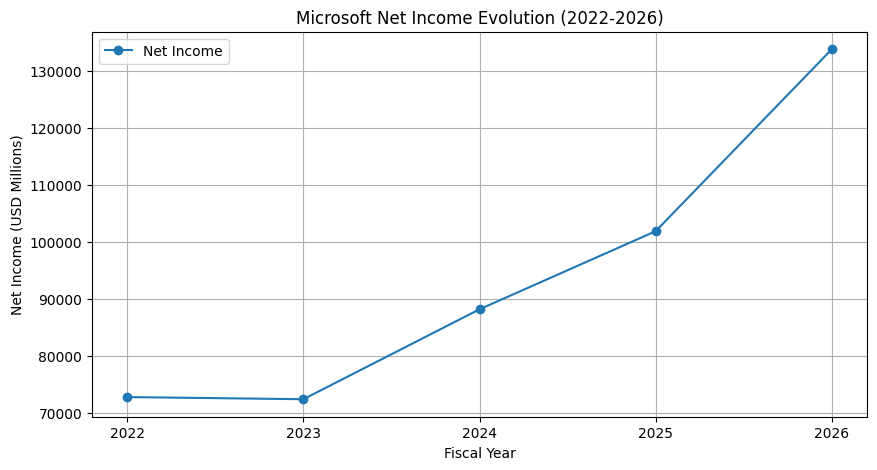

In [ ]:
# Créer une figure de 10 pouces par 5 pouces
plt.figure(figsize=(10, 5))

# Tracer l'évolution du bénéfice net
plt.plot(
    df["fiscal_year"],
    df["net_income_usd_millions"],
    marker="o",
    label="Net Income"
)

# Ajouter le titre et les noms des axes
plt.title("Microsoft Net Income Evolution (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Net Income (USD Millions)")

# Afficher les années sur l'axe horizontal
plt.xticks(df["fiscal_year"])

# Ajouter une grille et une légende
plt.grid(True)
plt.legend()

# Afficher le graphique
plt.show()

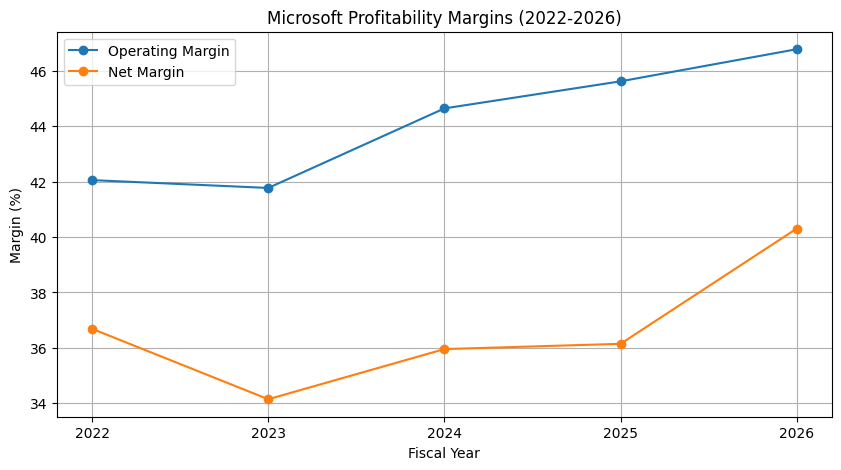

In [ ]:
# Créer une figure pour comparer les deux marges
plt.figure(figsize=(10, 5))

# Tracer la marge opérationnelle
plt.plot(
    df["fiscal_year"],
    df["operating_margin_%"],
    marker="o",
    label="Operating Margin"
)

# Tracer la marge nette
plt.plot(
    df["fiscal_year"],
    df["net_margin_%"],
    marker="o",
    label="Net Margin"
)

# Ajouter le titre et les noms des axes
plt.title("Microsoft Profitability Margins (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Margin (%)")

# Afficher les années
plt.xticks(df["fiscal_year"])

# Ajouter une grille et une légende
plt.grid(True)
plt.legend()

# Afficher le graphique
plt.show()

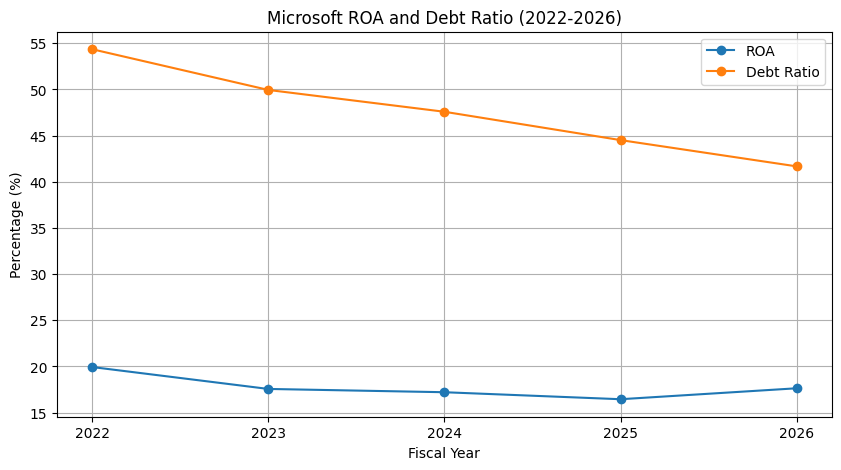

In [ ]:
# Créer une figure pour comparer le ROA et le Debt Ratio
plt.figure(figsize=(10, 5))

# Tracer le ROA : mesure la capacité à générer du bénéfice avec les actifs
plt.plot(
    df["fiscal_year"],
    df["ROA_%"],
    marker="o",
    label="ROA"
)

# Tracer le Debt Ratio : mesure la part des actifs financée par les dettes
plt.plot(
    df["fiscal_year"],
    df["debt_ratio_%"],
    marker="o",
    label="Debt Ratio"
)

# Ajouter le titre et les noms des axes
plt.title("Microsoft ROA and Debt Ratio (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Percentage (%)")

# Afficher les années
plt.xticks(df["fiscal_year"])

# Ajouter une grille et une légende
plt.grid(True)
plt.legend()

# Afficher le graphique
plt.show()

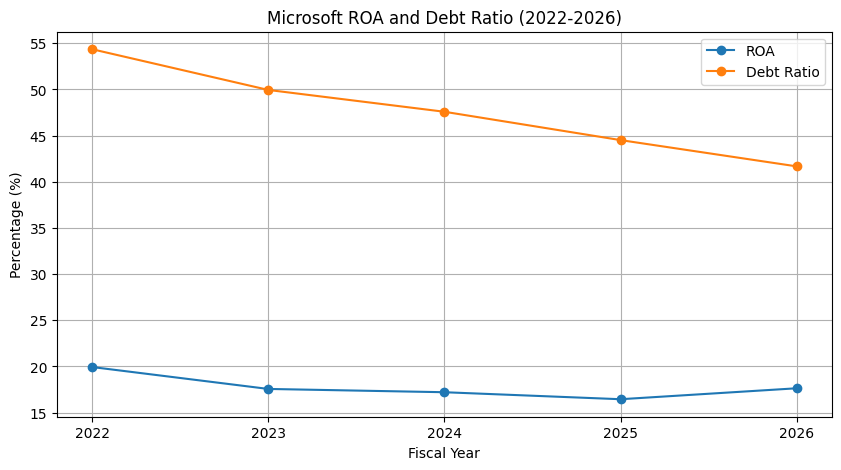

In [14]:
# Créer une figure pour comparer les deux indicateurs
plt.figure(figsize=(10, 5))

# Afficher l'évolution du ROA
plt.plot(
    df["fiscal_year"],
    df["ROA_%"],
    marker="o",
    label="ROA"
)

# Afficher l'évolution du Debt Ratio
plt.plot(
    df["fiscal_year"],
    df["debt_ratio_%"],
    marker="o",
    label="Debt Ratio"
)

# Ajouter le titre et les noms des axes
plt.title("Microsoft ROA and Debt Ratio (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Percentage (%)")

# Afficher les années
plt.xticks(df["fiscal_year"])

# Ajouter une grille et une légende
plt.grid(True)
plt.legend()

# Afficher le graphique
plt.show()

In [15]:
# Récupérer les données de la première année (2022)
first_year = df.iloc[0]

# Récupérer les données de la dernière année (2026)
last_year = df.iloc[-1]

# Calculer la croissance totale du chiffre d'affaires
revenue_change = (
    (last_year["revenue_usd_millions"] - first_year["revenue_usd_millions"])
    / first_year["revenue_usd_millions"] * 100
)

# Calculer la croissance totale du résultat opérationnel
operating_income_change = (
    (last_year["operating_income_usd_millions"] - first_year["operating_income_usd_millions"])
    / first_year["operating_income_usd_millions"] * 100
)

# Calculer la croissance totale du bénéfice net
net_income_change = (
    (last_year["net_income_usd_millions"] - first_year["net_income_usd_millions"])
    / first_year["net_income_usd_millions"] * 100
)

# Afficher les résultats
print("Financial Performance Comparison (2022-2026)")
print("---------------------------------------------")
print(f"Revenue Growth: {revenue_change:.2f}%")
print(f"Operating Income Growth: {operating_income_change:.2f}%")
print(f"Net Income Growth: {net_income_change:.2f}%")

Financial Performance Comparison (2022-2026)
---------------------------------------------
Revenue Growth: 67.37%
Operating Income Growth: 86.17%
Net Income Growth: 83.88%


In [16]:
# Créer un tableau récapitulatif des principaux indicateurs financiers
kpi_summary = df[[
    "fiscal_year",
    "revenue_usd_millions",
    "net_income_usd_millions",
    "operating_margin_%",
    "net_margin_%",
    "ROA_%",
    "debt_ratio_%"
]].copy()

# Arrondir les indicateurs à deux décimales
kpi_summary = kpi_summary.round(2)

# Afficher le tableau final des KPI
print("Microsoft Financial KPI Summary (2022-2026)")
display(kpi_summary)

Microsoft Financial KPI Summary (2022-2026)


,fiscal_year,revenue_usd_millions,net_income_usd_millions,operating_margin_%,net_margin_%,ROA_%,debt_ratio_%
0,2022,198270,72738,42.06,36.69,19.94,54.35
1,2023,211915,72361,41.77,34.15,17.56,49.94
2,2024,245122,88136,44.64,35.96,17.21,47.58
3,2025,281724,101832,45.62,36.15,16.45,44.51
4,2026,331839,133749,46.78,40.31,17.64,41.67


## Financial Analysis Conclusions – Microsoft (2022–2026)

1. **Revenue Growth:** Microsoft's revenue increased by 67.37% between 2022 and 2026, demonstrating strong business expansion.

2. **Operating Performance:** Operating income grew by 86.17%, exceeding revenue growth and indicating improved operating profitability.

3. **Net Profitability:** Net income increased by 83.88%, reflecting strong overall earnings growth.

4. **Operating Margin:** The operating margin improved from 42.06% in 2022 to 46.78% in 2026, showing improved operating efficiency.

5. **Net Margin:** The net margin reached 40.31% in 2026, compared with 36.69% in 2022.

6. **Asset Efficiency:** ROA declined from 19.94% in 2022 to 16.45% in 2025, before recovering to 17.64% in 2026.

7. **Financial Structure:** The debt ratio decreased from 54.35% to 41.67%, indicating a lower proportion of assets financed by liabilities.

8. **Overall Assessment:** Microsoft demonstrated strong revenue growth, improving profitability and a declining debt ratio over the five-year period.


In [17]:
# Create the charts output directory
import os

os.makedirs("outputs/charts", exist_ok=True)

# Save the four financial charts
# We will save each chart separately in the next step
print("Charts directory created successfully!")

Charts directory created successfully!


In [18]:
# Save the four financial charts as PNG files

# 1. Revenue Evolution
plt.figure(figsize=(10, 5))
plt.plot(df["fiscal_year"], df["revenue_usd_millions"], marker="o")
plt.title("Microsoft Revenue Evolution (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Revenue (USD Millions)")
plt.grid(True)
plt.savefig("outputs/charts/revenue_evolution.png", dpi=300, bbox_inches="tight")
plt.close()


# 2. Net Income Evolution
plt.figure(figsize=(10, 5))
plt.plot(df["fiscal_year"], df["net_income_usd_millions"], marker="o")
plt.title("Microsoft Net Income Evolution (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Net Income (USD Millions)")
plt.grid(True)
plt.savefig("outputs/charts/net_income_evolution.png", dpi=300, bbox_inches="tight")
plt.close()


# 3. Profitability Margins
plt.figure(figsize=(10, 5))
plt.plot(df["fiscal_year"], df["operating_margin_%"], marker="o", label="Operating Margin")
plt.plot(df["fiscal_year"], df["net_margin_%"], marker="o", label="Net Margin")
plt.title("Microsoft Profitability Margins (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Margin (%)")
plt.legend()
plt.grid(True)
plt.savefig("outputs/charts/profitability_margins.png", dpi=300, bbox_inches="tight")
plt.close()


# 4. ROA and Debt Ratio
plt.figure(figsize=(10, 5))
plt.plot(df["fiscal_year"], df["ROA_%"], marker="o", label="ROA")
plt.plot(df["fiscal_year"], df["debt_ratio_%"], marker="o", label="Debt Ratio")
plt.title("Microsoft ROA and Debt Ratio (2022-2026)")
plt.xlabel("Fiscal Year")
plt.ylabel("Percentage (%)")
plt.legend()
plt.grid(True)
plt.savefig("outputs/charts/roa_debt_ratio.png", dpi=300, bbox_inches="tight")
plt.close()


# Confirm that all charts have been saved
print("All four charts have been saved successfully!")

All four charts have been saved successfully!
